# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:** Sneha Kanjwani
- **Student ID:** 023-24-0273
- **Section:** H
- **GitHub:** https://github.com/snehakanjwani30/Machine-Learning-Labs
- **Kaggle:** https://www.kaggle.com/snehakanjwani
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [20]:
# YOUR CODE HERE
# Load and clean the dataset (reuse your Lab 2/3 pipeline)
import pandas as pd
import numpy as np

df = pd.read_csv('Telco-Customer-Churn.csv')

df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'], errors='coerce'
)

# Fill missing values
df['TotalCharges'] = df['TotalCharges'].fillna(
    df['TotalCharges'].median()
)

df.drop('customerID', axis=1, inplace=True)

df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print(df.head())
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No          No              No  Month-to-month   
1              Yes          No  

In [21]:
# YOUR CODE HERE
# One-hot encode, define X and y, train_test_split(..., stratify=y)
from sklearn.model_selection import train_test_split

df = pd.get_dummies(df, drop_first=True, dtype=int)

X = df.drop('Churn', axis=1)
y = df['Churn']
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)
print("Churn distribution:\n", y.value_counts())
#Interpretation: The categorical columns were converted into numerical form using one-hot encoding. The dataset was divided 
#into input features (X) and the target variable (y). Then, the data was split into 80% training data and 20% testing data. 
#Stratified sampling was used to maintain a similar distribution of churn classes in both sets.

X_train shape: (5634, 30)
X_test shape: (1409, 30)
y_train shape: (5634,)
y_test shape: (1409,)
Churn distribution:
 Churn
0    5174
1    1869
Name: count, dtype: int64


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [22]:
# YOUR CODE HERE — unscaled linear SVM
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
import time

svm_raw = SVC(kernel='linear', random_state=42)

start = time.time()
svm_raw.fit(X_train, y_train)
raw_time = time.time() - start

y_pred_raw = svm_raw.predict(X_test)

print("Unscaled Accuracy:", accuracy_score(y_test, y_pred_raw))
print("Unscaled F1-score:", f1_score(y_test, y_pred_raw))
print("Unscaled Training Time:", round(raw_time, 2), "seconds")
#Interpretation: A linear SVM was trained using the original, unscaled features. Its performance was evaluated using accuracy and F1-score, 
#and its training time was recorded. Since the features have different scales, some features may influence the SVM more than others.

Unscaled Accuracy: 0.7906316536550745
Unscaled F1-score: 0.5203252032520326
Unscaled Training Time: 1025.98 seconds


In [23]:
# YOUR CODE HERE — scaled linear SVM
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
import time

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

svm_scaled = SVC(kernel='linear', random_state=42)

start = time.time()
svm_scaled.fit(X_train_s, y_train)
scaled_time = time.time() - start

y_pred_scaled = svm_scaled.predict(X_test_s)

print("Scaled Accuracy:", accuracy_score(y_test, y_pred_scaled))
print("Scaled F1-score:", f1_score(y_test, y_pred_scaled))
print("Scaled Training Time:", round(scaled_time, 2), "seconds")
#Interpretation: StandardScaler was used to standardize the features before training the linear SVM. The scaler was fitted only 
#on the training data and then applied to the test data. Accuracy, F1-score, and training time were recorded to compare the scaled model 
#with the unscaled model.

Scaled Accuracy: 0.7892122072391767
Scaled F1-score: 0.5714285714285714
Scaled Training Time: 2.2 seconds


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

*Your answer:* The unscaled SVM achieved 79.06% accuracy and a 52.03% F1-score, taking 1025.98 seconds to train. The scaled SVM achieved 78.92% accuracy and a 57.14% F1-score, taking only 2.2 seconds. Accuracy remained almost the same, but the scaled model had a better F1-score and much lower training time. No convergence warnings were reported in either run.

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

*Your answer:* An SVM computes a decision boundary by finding the maximum-margin hyperplane between classes. When features have different scales, features with larger numerical ranges can have a greater influence on the boundary and margin. This can make optimization slower and affect model performance. Feature scaling puts features on a comparable scale, helping SVM find the boundary more efficiently.

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

*Your answer:* I will use the scaled SVM for all subsequent parts of the lab because it trained much faster (2.2 seconds compared to 1025.98 seconds) and achieved a higher F1-score (57.14% compared to 52.03%). Its accuracy was also almost the same as the unscaled model. Therefore, scaling makes training more efficient and improves the F1-score on this dataset.


---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [24]:
# YOUR CODE HERE — train linear / rbf / poly SVMs and collect metrics
import time
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {}
results = []

for kernel in ['linear', 'rbf', 'poly']:
    model = SVC(kernel=kernel, random_state=42)

    start = time.time()
    model.fit(X_train_s, y_train)
    training_time = time.time() - start

    y_pred = model.predict(X_test_s)

    models[kernel] = model

    results.append({
        'Kernel': kernel,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-score': f1_score(y_test, y_pred, zero_division=0),
        'Support Vectors': model.support_.shape[0]
    })

print("All three SVM models trained successfully.")
#Interpretation: Linear, RBF and polynomial SVMs were trained on the same scaled data. The models differ little in accuracy (0.7892-0.7928) 
#but more in recall (0.4652-0.5294), and the polynomial kernel used the most support vectors (2739).

All three SVM models trained successfully.


In [25]:
# YOUR CODE HERE — comparison table
results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

best_kernel = results_df.loc[
    results_df['F1-score'].idxmax(), 'Kernel'
]

print("\nBest kernel based on F1-score:", best_kernel)
#Interpretation: A comparison table was created to evaluate the performance of all three SVM kernels. The kernel with the highest F1-score 
#was selected as the best-performing model for the next step.

Kernel  Accuracy  Precision  Recall  F1-score  Support Vectors
linear    0.7892     0.6207  0.5294    0.5714             2569
   rbf    0.7928     0.6444  0.4893    0.5562             2661
  poly    0.7892     0.6421  0.4652    0.5395             2739

Best kernel based on F1-score: linear


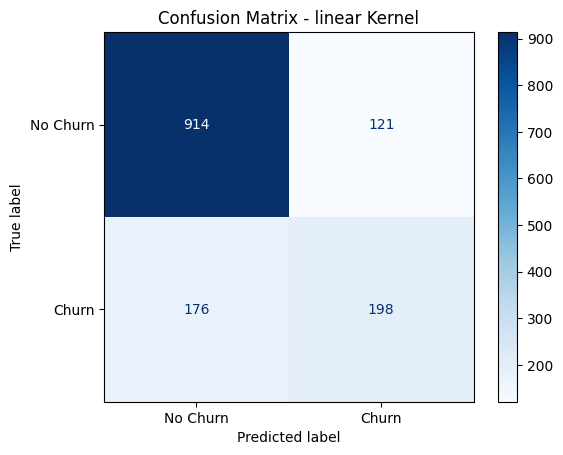

In [26]:
# YOUR CODE HERE — confusion matrix for the best kernel
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

best_model = models[best_kernel]
y_pred_best = best_model.predict(X_test_s)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_best,
    display_labels=['No Churn', 'Churn'],
    cmap='Blues'
)

plt.title(f'Confusion Matrix - {best_kernel} Kernel')
plt.show()
#Interpretation: The linear SVM (best F1 = 0.5714) catches about 198 of the 374 churners (recall 0.5294) and misses about 176. 
#It flags about 121 loyal customers wrongly (precision 0.6207). Most errors are missed churners, which is the costly mistake in this business setting.

**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

*Your answer:* The linear kernel produced the best F1-score of 57.14%, compared to 55.62% for RBF and 53.95% for the polynomial kernel. This is somewhat surprising because RBF can learn complex, non-linear decision boundaries and might be expected to perform better. However, a linear kernel can perform better when the data is sufficiently separable using a linear boundary.

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

*Your answer:* The polynomial kernel used the most support vectors, with 2,739 support vectors. A high support-vector count suggests that many training points contribute to defining the decision boundary. This may indicate a more complex boundary or that the classes are difficult to separate clearly.

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

*Your answer:* I carry RBF forward because it is within 0.015 F1 of linear (0.5562 vs 0.5714), has the highest accuracy (0.7928) and precision (0.6444), and has two tunable parameters (C, gamma) that can close the gap, whereas linear only has C.


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [27]:
# YOUR CODE HERE — PCA to 2 components, report explained variance ratio
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_s)
X_test_pca = pca.transform(X_test_s)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:",
      round(pca.explained_variance_ratio_.sum(), 4))
print("PCA training shape:", X_train_pca.shape)
#PCA reduced the original 30 features to 2 principal components for visualization. The explained variance ratio shows how much information 
#from the original dataset is retained by these two components. Some information may be lost during dimensionality reduction.

Explained variance ratio: [0.33246151 0.11980321]
Total explained variance: 0.4523
PCA training shape: (5634, 2)


In [28]:
# YOUR CODE HERE — train RBF SVMs at 3 different C values on the 2-D projection
from sklearn.svm import SVC

C_values = [0.01, 1, 100]
pca_models = {}

for c in C_values:
    model = SVC(kernel='rbf', C=c, random_state=42)
    model.fit(X_train_pca, y_train)

    pca_models[c] = model

    print(f"C = {c}")
    print("Number of support vectors:",
          model.support_.shape[0])
    print("-" * 30)
#The RBF SVM models were trained using three different values of C: 0.01, 1, and 100. A smaller C allows more training errors and 
#generally favors a smoother decision boundary, while a larger C penalizes training errors more strongly and may produce a more complex boundary. 
#The number of support vectors shows how many training points help define the decision boundary.

C = 0.01
Number of support vectors: 2997
------------------------------
C = 1
Number of support vectors: 2659
------------------------------
C = 100
Number of support vectors: 2631
------------------------------


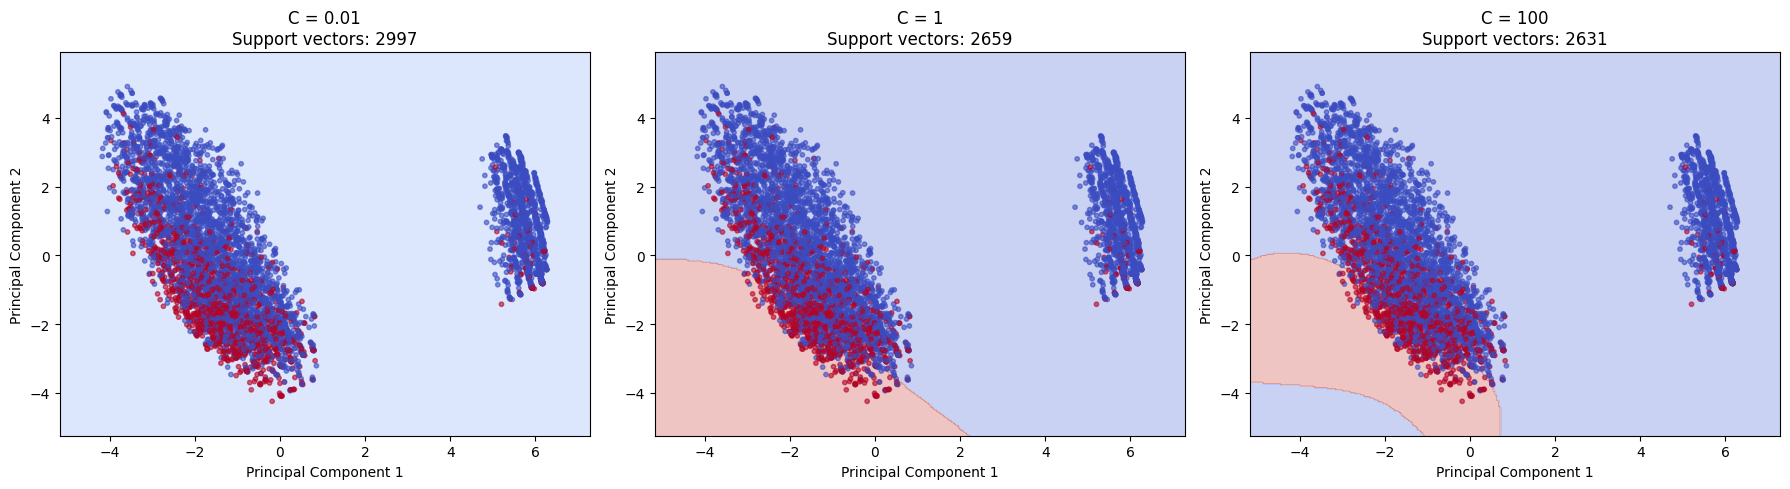

In [29]:
# YOUR CODE HERE — plot decision boundary for each C (mesh grid + contourf)
import numpy as np
import matplotlib.pyplot as plt

x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, c in zip(axes, C_values):
    model = pca_models[c]

    Z = model.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')

    ax.scatter(
        X_train_pca[:, 0],
        X_train_pca[:, 1],
        c=y_train,
        cmap='coolwarm',
        s=10,
        alpha=0.6
    )

    ax.set_title(
        f'C = {c}\nSupport vectors: {model.support_.shape[0]}'
    )
    ax.set_xlabel('Principal Component 1')
    ax.set_ylabel('Principal Component 2')

plt.tight_layout()
plt.show()
#Interpretation: At C = 0.01 the whole plotted region is predicted "No Churn", so the model underfits. At C = 1 a curved churn region appears 
#in the lower-left, and at C = 100 it is larger and more irregular, so the boundary grows more complex as C increases. Red and blue points 
#overlap heavily, and with PCA explaining only 45.23% of the variance this 2-D view is only a rough illustration of the 30-feature model.

**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

*Your answer:* At C = 0.01 the boundary is essentially flat: the whole plotted region is predicted as “No Churn”. At C = 1 a curved pink (Churn) region appears in the lower-left, and at C = 100 that region is larger and more irregular, with an extra blue sliver at the bottom. So the boundary becomes more complex as C increases.

(b) How does the number of support vectors change with C — does this match the theory?

*Your answer:* The number of support vectors decreased as C increased. For C = 0.01, there were 2,997 support vectors; for C = 1, there were 2,659; and for C = 100, there were 2,631. This matches the general expectation that a smaller C allows a wider margin and may result in more support vectors. However, the exact trend depends on the dataset.

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*Your answer:* C = 0.01 is underfitting: it predicts one class everywhere and ignores the red churners entirely. C = 100 is the most flexible, with the most irregular boundary, so it is the closest to overfitting. However, even at C = 100 the pink region sits mostly outside the data cloud, because red and blue points overlap heavily in this 2-D view. The classes are not well separated in these two components.

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*Your answer:* PCA reduced the original 30 features to 2 principal components, which explain a total of 45.23% of the variance. Therefore, 54.77% of the variance is not represented in this 2-D projection. The plot cannot show the complete decision boundary of the original high-dimensional SVM and may give a misleading impression of class separation or model performance.


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [30]:
# YOUR CODE HERE — define param_grid and run GridSearchCV
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.1, 1, 10],
    'gamma': [0.01, 0.1, 1]
}

gs = GridSearchCV(
    estimator=SVC(kernel='rbf', random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

gs.fit(X_train_s, y_train)

print("Best parameters:", gs.best_params_)
print("Best cross-validation F1-score:", round(gs.best_score_, 4))
print("Total combinations tested:", len(gs.cv_results_['params']))
#GridSearchCV tested nine combinations of C and gamma using 5-fold cross-validation. It selected the combination with the highest mean 
#validation F1-score. Only the scaled training data was used for hyperparameter tuning, keeping the test set separate for final evaluation.

Best parameters: {'C': 10, 'gamma': 0.01}
Best cross-validation F1-score: 0.5853
Total combinations tested: 9


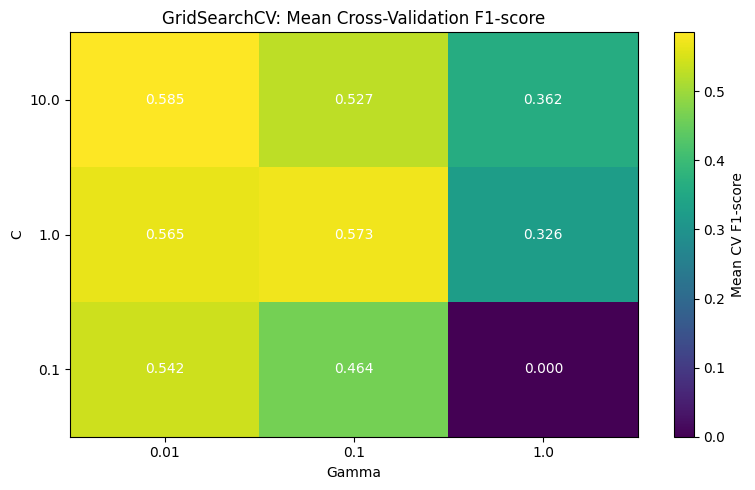

In [31]:
# YOUR CODE HERE — heatmap of mean CV F1-score over the C x gamma grid
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

cv_results_df = pd.DataFrame(gs.cv_results_)

heatmap_data = cv_results_df.pivot(
    index='param_C',
    columns='param_gamma',
    values='mean_test_score'
)

heatmap_data = heatmap_data.astype(float).sort_index()
heatmap_data = heatmap_data.reindex(
    sorted(heatmap_data.columns, key=float),
    axis=1
)

plt.figure(figsize=(8, 5))

plt.imshow(
    heatmap_data.values,
    cmap='viridis',
    aspect='auto',
    origin='lower'
)

plt.xticks(
    range(len(heatmap_data.columns)),
    [str(x) for x in heatmap_data.columns]
)
plt.yticks(
    range(len(heatmap_data.index)),
    [str(x) for x in heatmap_data.index]
)

plt.xlabel('Gamma')
plt.ylabel('C')
plt.title('GridSearchCV: Mean Cross-Validation F1-score')

plt.colorbar(label='Mean CV F1-score')

for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):
        plt.text(
            j, i,
            f'{heatmap_data.iloc[i, j]:.3f}',
            ha='center',
            va='center',
            color='white'
        )

plt.tight_layout()
plt.show()
# Interpretation: The best cell is C=10, gamma=0.01 (0.585), but C=1 with gamma=0.1 (0.573) and C=1 with gamma=0.01 (0.565) are close, so there 
#is a fairly stable region at low gamma. Gamma=1 performs badly (0.33-0.36, and 0.000 at C=0.1 where the model predicts no churners at all),
#so the model is much more sensitive to gamma than to C.

Best parameters: {'C': 10, 'gamma': 0.01}
Best CV F1-score: 0.5853

Test Accuracy: 0.7885
Test Precision: 0.6275
Test Recall: 0.5
Test F1-score: 0.5565


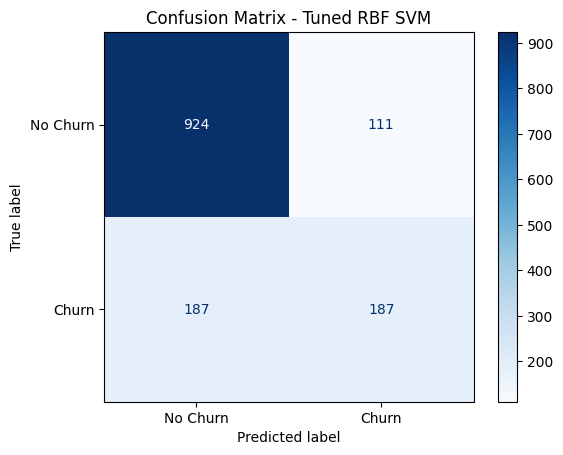

In [32]:
# YOUR CODE HERE — refit best estimator, evaluate on test set
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

best_svm = gs.best_estimator_

y_pred_tuned = best_svm.predict(X_test_s)

print("Best parameters:", gs.best_params_)
print("Best CV F1-score:", round(gs.best_score_, 4))

print("\nTest Accuracy:", round(accuracy_score(y_test, y_pred_tuned), 4))
print("Test Precision:", round(precision_score(y_test, y_pred_tuned, zero_division=0), 4))
print("Test Recall:", round(recall_score(y_test, y_pred_tuned, zero_division=0), 4))
print("Test F1-score:", round(f1_score(y_test, y_pred_tuned, zero_division=0), 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned,
    display_labels=['No Churn', 'Churn'],
    cmap='Blues'
)

plt.title('Confusion Matrix - Tuned RBF SVM')
plt.show()
#Interpretation: The tuned RBF model (C=10, gamma=0.01) has recall 0.50, so it still misses about half of the churners (about 187 of 374), 
#and precision 0.6275. Its test F1 (0.5565) is lower than the cross-validated F1 (0.5853), a gap of about 0.029, which is small, so it generalises 
#reasonably.

**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*Your answer:* The best hyperparameter values were C = 10 and gamma = 0.01. The corresponding mean cross-validated F1-score was 0.5853 (58.53%). GridSearchCV tested nine combinations using 5-fold cross-validation.

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*Your answer:* There is a rough best region at low gamma and higher C: 0.585 (C=10, gamma=0.01), 0.573 (C=1, gamma=0.1) and 0.565 (C=1, gamma=0.01) are all close. Gamma matters more than C: at gamma=1, scores collapse to 0.33–0.36, and at C=0.1, gamma=1 the score is 0.000 (the model predicts “No Churn” for everyone). The model is fairly stable in the low-gamma region but sensitive to large gamma. Also, the best value sits at a corner of my grid, so a wider grid (e.g. C=100, gamma=0.001) might do slightly better.

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*Your answer:* The cross-validated F1-score was 58.53%, while the test-set F1-score was 55.65%, giving a gap of 2.88 percentage points. These scores are reasonably close, suggesting that the model generalizes fairly consistently to unseen data. A large gap could indicate overfitting or that the cross-validation results do not represent the test data well.

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*Your answer:* The untuned RBF model achieved 79.28% accuracy, 64.44% precision, 48.93% recall, and a 55.62% F1-score. The tuned RBF model achieved 78.85% accuracy, 62.75% precision, 50.00% recall, and a 55.65% F1-score. Tuning slightly improved F1-score and recall, but accuracy and precision decreased. Therefore, tuning provided only a very small improvement in F1-score and did not substantially improve overall test performance.


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


            Model  Precision  Recall  F1-score
Without balancing     0.6275  0.5000    0.5565
   With balancing     0.5070  0.7781    0.6139


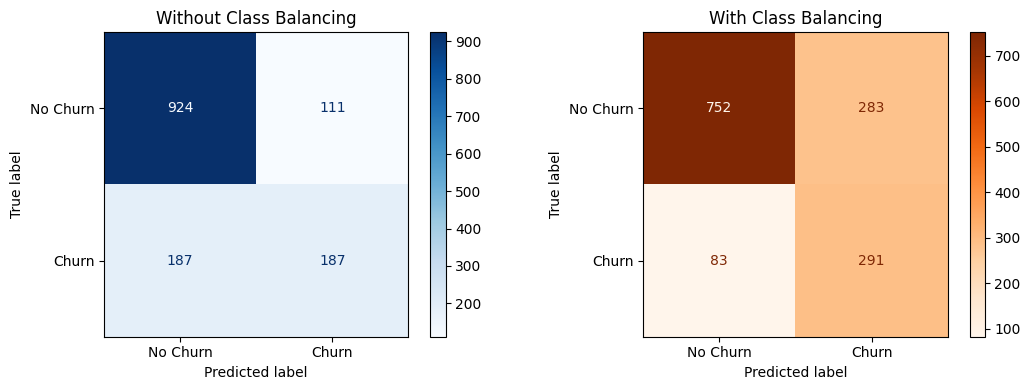

In [33]:
# YOUR CODE HERE — class_weight=None vs 'balanced' comparison
from sklearn.svm import SVC
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)
import pandas as pd
import matplotlib.pyplot as plt

svm_none = SVC(
    kernel='rbf',
    C=10,
    gamma=0.01,
    class_weight=None,
    random_state=42
)

svm_none.fit(X_train_s, y_train)
y_pred_none = svm_none.predict(X_test_s)

svm_balanced = SVC(
    kernel='rbf',
    C=10,
    gamma=0.01,
    class_weight='balanced',
    random_state=42
)

svm_balanced.fit(X_train_s, y_train)
y_pred_balanced = svm_balanced.predict(X_test_s)

results_part5 = pd.DataFrame([
    {
        'Model': 'Without balancing',
        'Precision': precision_score(y_test, y_pred_none, zero_division=0),
        'Recall': recall_score(y_test, y_pred_none, zero_division=0),
        'F1-score': f1_score(y_test, y_pred_none, zero_division=0)
    },
    {
        'Model': 'With balancing',
        'Precision': precision_score(y_test, y_pred_balanced, zero_division=0),
        'Recall': recall_score(y_test, y_pred_balanced, zero_division=0),
        'F1-score': f1_score(y_test, y_pred_balanced, zero_division=0)
    }
])

print(results_part5.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_none,
    display_labels=['No Churn', 'Churn'],
    cmap='Blues',
    ax=axes[0]
)
axes[0].set_title('Without Class Balancing')

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_balanced,
    display_labels=['No Churn', 'Churn'],
    cmap='Oranges',
    ax=axes[1]
)
axes[1].set_title('With Class Balancing')

plt.tight_layout()
plt.show()
#Interpretation: Class balancing raised recall from 0.5000 to 0.7781 (about 187 to 291 churners caught) and F1 from 0.5565 to 0.6139, 
#but precision dropped from 0.6275 to 0.5070, so false alarms rose from about 111 to about 283 loyal customers flagged. The model trades 
#precision for recall.

Balanced Model ROC-AUC: 0.8191


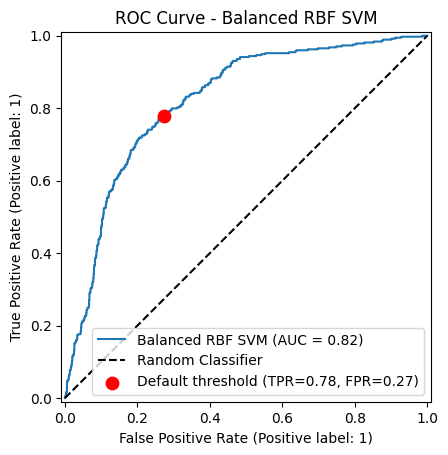

In [34]:
# YOUR CODE HERE — ROC or Precision-Recall curve
from sklearn.metrics import RocCurveDisplay, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt

y_scores_balanced = svm_balanced.decision_function(X_test_s)
roc_auc = roc_auc_score(y_test, y_scores_balanced)
print("Balanced Model ROC-AUC:", round(roc_auc, 4))

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_balanced).ravel()
op_tpr = tp / (tp + fn)
op_fpr = fp / (fp + tn)

RocCurveDisplay.from_predictions(y_test, y_scores_balanced, name='Balanced RBF SVM')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.scatter(op_fpr, op_tpr, color='red', s=80, zorder=5,
            label=f'Default threshold (TPR={op_tpr:.2f}, FPR={op_fpr:.2f})')
plt.title('ROC Curve - Balanced RBF SVM')
plt.legend()
plt.show()
#Interpretation: The balanced SVM has an ROC-AUC of 0.8191, so it ranks a random churner above a random non-churner about 82% of the time, 
#which is good discrimination (0.5 would be random guessing). The red dot marks the default threshold (decision score > 0): it sits at 
#TPR ≈ 0.78 (the recall of 0.7781), with FPR ≈ 0.27, meaning roughly 78% of churners are caught but about 27% of loyal customers are also flagged.
#Moving the threshold up would cut false alarms at the cost of missing more churners; moving it down does the opposite.

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*Your answer:* When class_weight='balanced' was applied, precision decreased from 62.75% to 50.70%, a decrease of 12.05 percentage points. Recall increased from 50.00% to 77.81%, an increase of 27.81 percentage points. This means the balanced model detected more actual churners but also incorrectly flagged more loyal customers as churners.

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*Your answer:* In this business scenario, missing an actual churner (false negative) may be more costly because the company loses the opportunity to retain that customer. Therefore, I would deploy the balanced model because its recall is higher at 77.81%, compared to 50.00% without balancing. Although it has lower precision, it identifies more customers who are likely to churn, allowing the company to take retention actions.

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*Your answer:* To obtain actual probability estimates from an SVM, I would enable probability=True in SVC(). However, in this experiment, we used decision_function() to obtain decision scores for plotting the ROC curve. These scores are not actual probabilities; they represent the model's confidence relative to its decision boundary.


---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [35]:
# YOUR CODE HERE — cross-model comparison table
import time                                   
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'KNN': KNeighborsClassifier(),
    'SVM': SVC(kernel='rbf', C=10, gamma=0.01, class_weight='balanced',
               random_state=42)
}
results = []
train_times = {}                              
for name, model in models.items():
    start = time.time()                      
    model.fit(X_train_s, y_train)
    train_times[name] = round(time.time() - start, 3)  
    y_pred = model.predict(X_test_s)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-score': f1_score(y_test, y_pred, zero_division=0)
    })
comparison_df = pd.DataFrame(results)
print(comparison_df.round(4).to_string(index=False))
print("\nTraining time (seconds):", train_times)    
#Interpretation: On the same train/test split, the balanced SVM has the highest F1-score (0.6139) and by far the highest recall (0.7781), 
#narrowly ahead of Logistic Regression (F1 0.6092, recall 0.5668). Logistic Regression has the best accuracy (0.8070) and precision (0.6584), 
#so it makes fewer false alarms. Decision Tree (F1 0.5020) and KNN (F1 0.5123) perform worst. SVM's lower accuracy (0.7402) and precision (0.5070) 
#are the cost of class balancing, which flags more customers as likely churners.

              Model  Accuracy  Precision  Recall  F1-score
      Decision Tree    0.7410     0.5125  0.4920    0.5020
      Random Forest    0.7857     0.6216  0.4920    0.5493
Logistic Regression    0.8070     0.6584  0.5668    0.6092
                KNN    0.7473     0.5253  0.5000    0.5123
                SVM    0.7402     0.5070  0.7781    0.6139

Training time (seconds): {'Decision Tree': 0.051, 'Random Forest': 1.701, 'Logistic Regression': 0.055, 'KNN': 0.003, 'SVM': 3.932}


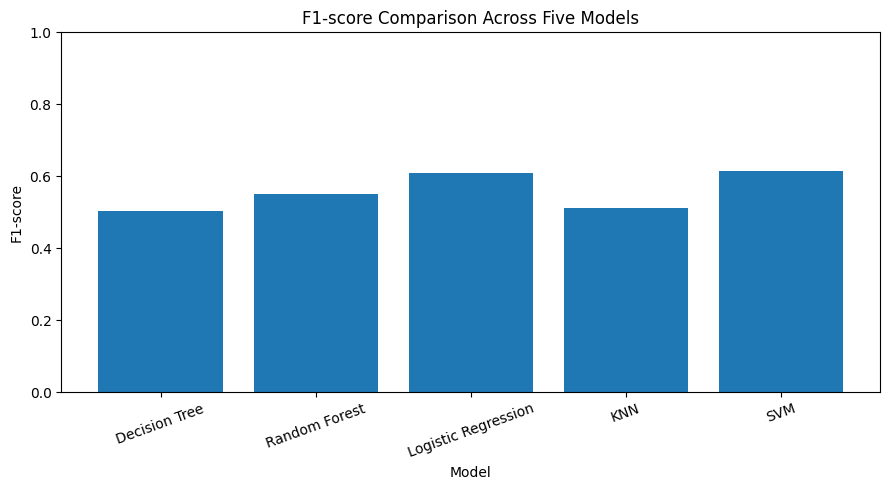

In [36]:
# YOUR CODE HERE — bar chart of F1-score across models
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.bar(comparison_df['Model'], comparison_df['F1-score'])
plt.title('F1-score Comparison Across Five Models')
plt.xlabel('Model')
plt.ylabel('F1-score')
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()
#Interpretation: The balanced SVM (0.6139) and Logistic Regression (0.6092) are nearly tied for the highest F1, with Random Forest (0.5493) 
#behind them. KNN (0.5123) and Decision Tree (0.5020) are the lowest. The F1 difference between the top two is tiny, so recall and precision 
#should decide the final choice.

**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*Your answer:* The balanced SVM wins on F1-score with 0.6139, narrowly ahead of Logistic Regression at 0.6092. SVM also wins on recall with 0.7781 (Logistic Regression: 0.5668). So the same model wins both metrics, though the F1 margin over Logistic Regression is very small.
(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*Your answer:* SVM was the slowest model to train: it took 3.932 s, compared with 0.051 s for Decision Tree, 1.701 s for Random Forest and 0.055 s for Logistic Regression. In return, the balanced SVM gave the highest recall (0.7781, vs 0.5668 for Logistic Regression) and the highest F1-score (0.6139). The extra cost is only a few seconds on this dataset of about 7,000 customers, so I think it was worth it, because catching more churners is the main business goal. However, the F1 advantage over Logistic Regression (0.6139 vs 0.6092) is tiny, and Logistic Regression trained about 70 times faster with higher accuracy (0.8070 vs 0.7402) and precision (0.6584 vs 0.5070). So the extra cost is justified mainly by recall, not by overall performance.

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

*Your answer:* I recommend the balanced SVM. It has the highest F1 (0.6139) and by far the highest recall (0.7781 vs 0.5668 for Logistic Regression). The cost is lower precision (0.5070 vs 0.6584) and lower accuracy (0.7402 vs 0.8070), meaning more loyal customers get flagged. I accept this because missing a churner costs more than a wasted retention offer. If the company’s retention budget is tight, Logistic Regression is a reasonable alternative.

---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [37]:
# YOUR CODE HERE — generate and save svm_predictions.csv
import pandas as pd

final_model = SVC(
    kernel='rbf',
    C=10,
    gamma=0.01,
    class_weight='balanced',
    random_state=42
)

final_model.fit(X_train_s, y_train)

y_pred = final_model.predict(X_test_s)
y_score = final_model.decision_function(X_test_s)

predictions_df = pd.DataFrame({
    'True_Label': y_test.to_numpy() if hasattr(y_test, 'to_numpy') else y_test,
    'Predicted_Label': y_pred,
    'Churn_Score': y_score
})

predictions_df.to_csv('svm_predictions.csv', index=False)

print("Predictions saved to svm_predictions.csv")
print(predictions_df.head())

Predictions saved to svm_predictions.csv
   True_Label  Predicted_Label  Churn_Score
0           0                0    -1.368272
1           0                1     1.405616
2           0                0    -1.511366
3           0                1     0.573208
4           0                0    -1.574256


**Executive Summary**

This project compared five machine learning algorithms for predicting customer churn: Decision Tree, Random Forest, Logistic Regression, KNN, and SVM. Based on the comparison, the balanced SVM was selected because it achieved the highest recall of 77.81% and an F1-score of 61.39%. Its precision was 50.70%, meaning that some customers predicted to churn were actually loyal customers. Compared with the unbalanced SVM, class balancing increased recall from 50.00% to 77.81% but reduced precision from 62.75% to 50.70%. This trade-off was accepted because identifying more potential churners can help the company take customer-retention actions. Logistic Regression performed better in accuracy, achieving 80.70%, so it could be preferable when overall accuracy and precision are more important. One limitation is that the analysis used a single train-test split, and the results may differ on new customer data.

**Final Reflection**
(a) What was the single most surprising result in this lab?

*Your answer:* The most surprising result was that class balancing increased SVM recall from 50.00% to 77.81%, while precision decreased from 62.75% to 50.70%. This showed that class balancing helped identify more actual churners but also increased false positives.

(b) If you had one more hour, what would you try next?

*Your answer:* I would try more hyperparameter combinations using GridSearchCV and compare the models using cross-validation. I would also experiment with different classification thresholds to improve the balance between precision and recall and evaluate whether the model can detect more churners without generating too many false positives.
